# 이커머스 멀티모달 데이터 분석 및 RFM 고객 세분화 리포트

본 노트북은 `src/pipeline.py`의 `DataAnalyzer` 클래스를 사용하여 다음 과정을 수행합니다.
1. 데이터 로드 및 기본 탐색 (`info`, `describe`, `head`)
2. 멀티모달 피처 엔지니어링 (NumPy 벡터 연산 기반 이미지 통계/다운샘플링 + 텍스트 특성)
3. GroupBy 결측치 대치 및 IQR 이상치 탐지·처리
4. 기술통계 및 상관분석
5. 필수 시각화 6종 (히스토그램, 박스플롯, 막대그래프, 히트맵, 산점도, 라인차트)
6. RFM 기반 고객 세분화 (VIP, Loyal, New, Churned)

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path('..').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.pipeline import DataAnalyzer

plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')

## 1. 데이터 로드 및 기본 탐색
`DataAnalyzer`를 초기화하고 `ecommerce_transactions.csv`와 `product_images.npy`를 로드합니다.

In [2]:
analyzer = DataAnalyzer(
    csv_path='../data/ecommerce_transactions.csv',
    images_path='../data/product_images.npy',
)
df_raw, images = analyzer.load_data()
print(f'Tabular shape: {df_raw.shape}, Images shape: {images.shape}, dtype: {images.dtype}')
df_raw.info()
display(df_raw.head())
display(df_raw.describe(include='all').T)

Tabular shape: (2000, 14), Images shape: (2000, 80, 60, 3), dtype: uint8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   product_id    2000 non-null   int64         
 1   product_name  2000 non-null   object        
 2   gender        2000 non-null   object        
 3   category      2000 non-null   object        
 4   sub_category  2000 non-null   object        
 5   base_colour   2000 non-null   object        
 6   season        2000 non-null   object        
 7   year          2000 non-null   float64       
 8   customer_id   2000 non-null   object        
 9   order_date    2000 non-null   datetime64[ns]
 10  unit_price    1950 non-null   float64       
 11  quantity      2000 non-null   int64         
 12  amount        1950 non-null   float64       
 13  image_id      2000 non-null   int64         
dtypes: datetime64[n

,product_id,product_name,gender,category,sub_category,base_colour,season,year,customer_id,order_date,unit_price,quantity,amount,image_id
0,15970,Turtle Check Men Navy Blue Shirt,Men,Apparel,Topwear,Navy Blue,Fall,2011.0,CUST_0323,2025-05-15 02:04:58,28.66,3,85.98,0
1,39386,Peter England Men Party Blue Jeans,Men,Apparel,Bottomwear,Blue,Summer,2012.0,CUST_0281,2025-01-23 19:57:13,12.52,1,12.52,1
2,59263,Titan Women Silver Watch,Women,Accessories,Watches,Silver,Winter,2016.0,CUST_0194,2025-05-04 05:07:38,48.51,2,97.02,2
3,21379,Manchester United Men Solid Black Track Pants,Men,Apparel,Bottomwear,Black,Fall,2011.0,CUST_0047,2025-10-03 13:22:49,36.29,2,72.58,3
4,53759,Puma Men Grey T-shirt,Men,Apparel,Topwear,Grey,Summer,2012.0,CUST_0193,2025-10-25 17:42:53,5.00,4,20.00,4


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
product_id,2000.0,NaN,NaN,NaN,29555.521,1607.0,14660.5,28237.0,44511.75,59897.0,17009.487425
product_name,2000,1877,Lucera Women Silver Ring,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,2000,5,Men,989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2000,5,Apparel,921,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sub_category,2000,33,Topwear,651,NaN,NaN,NaN,NaN,NaN,NaN,NaN
base_colour,2000,44,Black,465,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,2000,4,Summer,963,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2012.819,2010.0,2011.0,2012.0,2015.0,2019.0,2.13249
customer_id,2000,280,CUST_0113,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,2000,NaN,NaN,NaN,2025-06-27 15:02:04.067499776,2025-01-01 03:39:07,2025-03-31 12:45:19.500000,2025-06-25 06:46:11.500000,2025-09-23 09:10:39.500000,2025-12-31 19:46:42,NaN


### 기본 탐색 해석
- **수치 근거**: 총 `2,000`건, `14`개 컬럼과 `(2000, 80, 60, 3)` 이미지 배열이 1:1로 매칭되어 있으며, `unit_price`와 `amount`에 각 `50`건(2.5%)의 결측치가 존재하고 `unit_price` 최댓값은 평균 대비 크게 높은 극단값을 포함하고 있습니다.
- **시사점**: 결측치 대치(GroupBy)와 이상치 완화(IQR)를 선행해야 이후 매출 통계와 RFM 세그먼트가 왜곡되지 않습니다.

## 2. 멀티모달 피처 엔지니어링 (NumPy 벡터 연산)
반복문(`for` loop) 없이 NumPy 배열 축 연산(`mean`, `std`, 슬라이싱 `[:, ::2, ::2, :]`)으로 이미지 통계 특성을 추출하고, 상품명(`product_name`)의 문자열 길이와 단어 수를 계산합니다.

In [3]:
df_feat = analyzer.extract_multimodal_features(downsample_step=2)
display(df_feat[['product_name', 'name_length', 'word_count', 'img_mean', 'img_std', 'img_downsampled_mean']].head())

,product_name,name_length,word_count,img_mean,img_std,img_downsampled_mean
0,Turtle Check Men Navy Blue Shirt,32,6,196.641250,71.148445,196.174444
1,Peter England Men Party Blue Jeans,34,6,195.927708,80.758664,195.396389
2,Titan Women Silver Watch,24,4,244.256042,23.115626,244.327500
3,Manchester United Men Solid Black Track Pants,45,7,197.872986,84.923207,196.626944
4,Puma Men Grey T-shirt,21,4,189.966806,79.938437,191.168611


## 3. 결측치 대치 및 IQR 이상치 처리
카테고리별 중앙값으로 `unit_price` 결측치를 대치한 뒤, 처리 전 데이터와 IQR Capping 처리 후 분포를 비교합니다.

In [ ]:
#표에서 각 컬럼별 빈칸(NaN) 개수를 센 뒤, 아직 빈칸이 1개 이상 남아있는 컬럼만 골라서 출력하는 코드입니다."
df_imputed = analyzer.handle_missing_values(group_col='category', target_cols=['unit_price'], strategy='median')
print('Missing values after imputation:\n', df_imputed.isna().sum()[df_imputed.isna().sum() > 0])

price_before = df_imputed['unit_price'].copy()
outlier_price = analyzer.detect_outliers(column='unit_price', iqr_multiplier=1.5, action='cap')
outlier_qty = analyzer.detect_outliers(column='quantity', iqr_multiplier=1.5, action='cap')
price_after = analyzer.df['unit_price'].copy()

print('unit_price outlier report:', {k: v for k, v in outlier_price.items() if k in ['q1', 'q3', 'iqr', 'upper_bound', 'outlier_count']})
print('quantity outlier report:', {k: v for k, v in outlier_qty.items() if k in ['q1', 'q3', 'iqr', 'upper_bound', 'outlier_count']})

Missing values after imputation:
 Series([], dtype: int64)
unit_price outlier report: {'q1': 20.017500000000002, 'q3': 44.3125, 'iqr': 24.294999999999998, 'upper_bound': 80.755, 'outlier_count': 49}
quantity outlier report: {'q1': 2.0, 'q3': 4.0, 'iqr': 2.0, 'upper_bound': 7.0, 'outlier_count': 15}


## 4. 기술통계 및 상관분석
주요 수치형 변수에 대해 평균, 중앙값, 표준편차, 사분위수(Q1, Q2, Q3) 및 상관계수 행렬을 계산합니다.

In [5]:
num_cols = ['unit_price', 'quantity', 'amount', 'img_mean', 'img_std', 'word_count', 'name_length']
stats = analyzer.compute_statistics(numeric_cols=num_cols)
display(stats['summary'].round(2))
display(stats['corr_matrix'].round(3))

,mean,median,std,q1,q2,q3
unit_price,33.15,30.29,18.40,20.02,30.29,44.31
quantity,2.52,2.00,1.18,2.00,2.00,4.00
amount,83.05,66.43,63.93,34.77,66.43,114.70
img_mean,214.09,215.99,22.15,199.30,215.99,231.12
img_std,64.13,66.47,20.77,50.37,66.47,79.99
word_count,5.81,6.00,1.40,5.00,6.00,7.00
name_length,34.54,34.00,8.47,28.00,34.00,39.00


,unit_price,quantity,amount,img_mean,img_std,word_count,name_length
unit_price,1.000,-0.025,0.707,0.122,-0.038,0.009,0.001
quantity,-0.025,1.000,0.599,0.014,-0.019,0.005,-0.001
amount,0.707,0.599,1.000,0.108,-0.048,0.009,0.011
img_mean,0.122,0.014,0.108,1.000,-0.818,-0.031,-0.053
img_std,-0.038,-0.019,-0.048,-0.818,1.000,0.019,0.024
word_count,0.009,0.005,0.009,-0.031,0.019,1.000,0.885
name_length,0.001,-0.001,0.011,-0.053,0.024,0.885,1.000


### 통계 및 상관분석 해석
- **수치 근거 1 (중심경향 및 산포)**: `unit_price`의 평균은 약 `33.15`, 중앙값은 `30.29`, 표준편차는 `18.40`이며 `amount`의 사분위수는 Q1 `34.77`, Q2 `66.43`, Q3 `114.70`으로 우측 꼬리가 긴 분포를 보입니다.
- **수치 근거 2 (상관관계 쌍 1 — `img_mean` vs `img_std`)**: 두 변수의 상관계수는 약 `-0.818`로 강한 음의 상관을 나타냅니다. 밝은 흰 배경 비중이 높은 상품 이미지일수록 평균 픽셀 밝기가 높아지는 대신 픽셀 간 명암 편차가 줄어든다는 시사점을 제공합니다.
- **수치 근거 3 (상관관계 쌍 2 — `word_count` vs `name_length`)**: 상관계수가 약 `0.885`로 강한 양의 상관을 보이며, `unit_price`와 `amount` 역시 `0.707`의 높은 양의 상관을 보여 고가 카테고리가 총매출에 미치는 영향이 큼을 시사합니다.

## 5. 시각화 6종
히스토그램, 박스플롯(이상치 처리 전후 비교), 막대그래프, 히트맵, 산점도, 라인차트(월별 매출 추이)를 작성합니다.

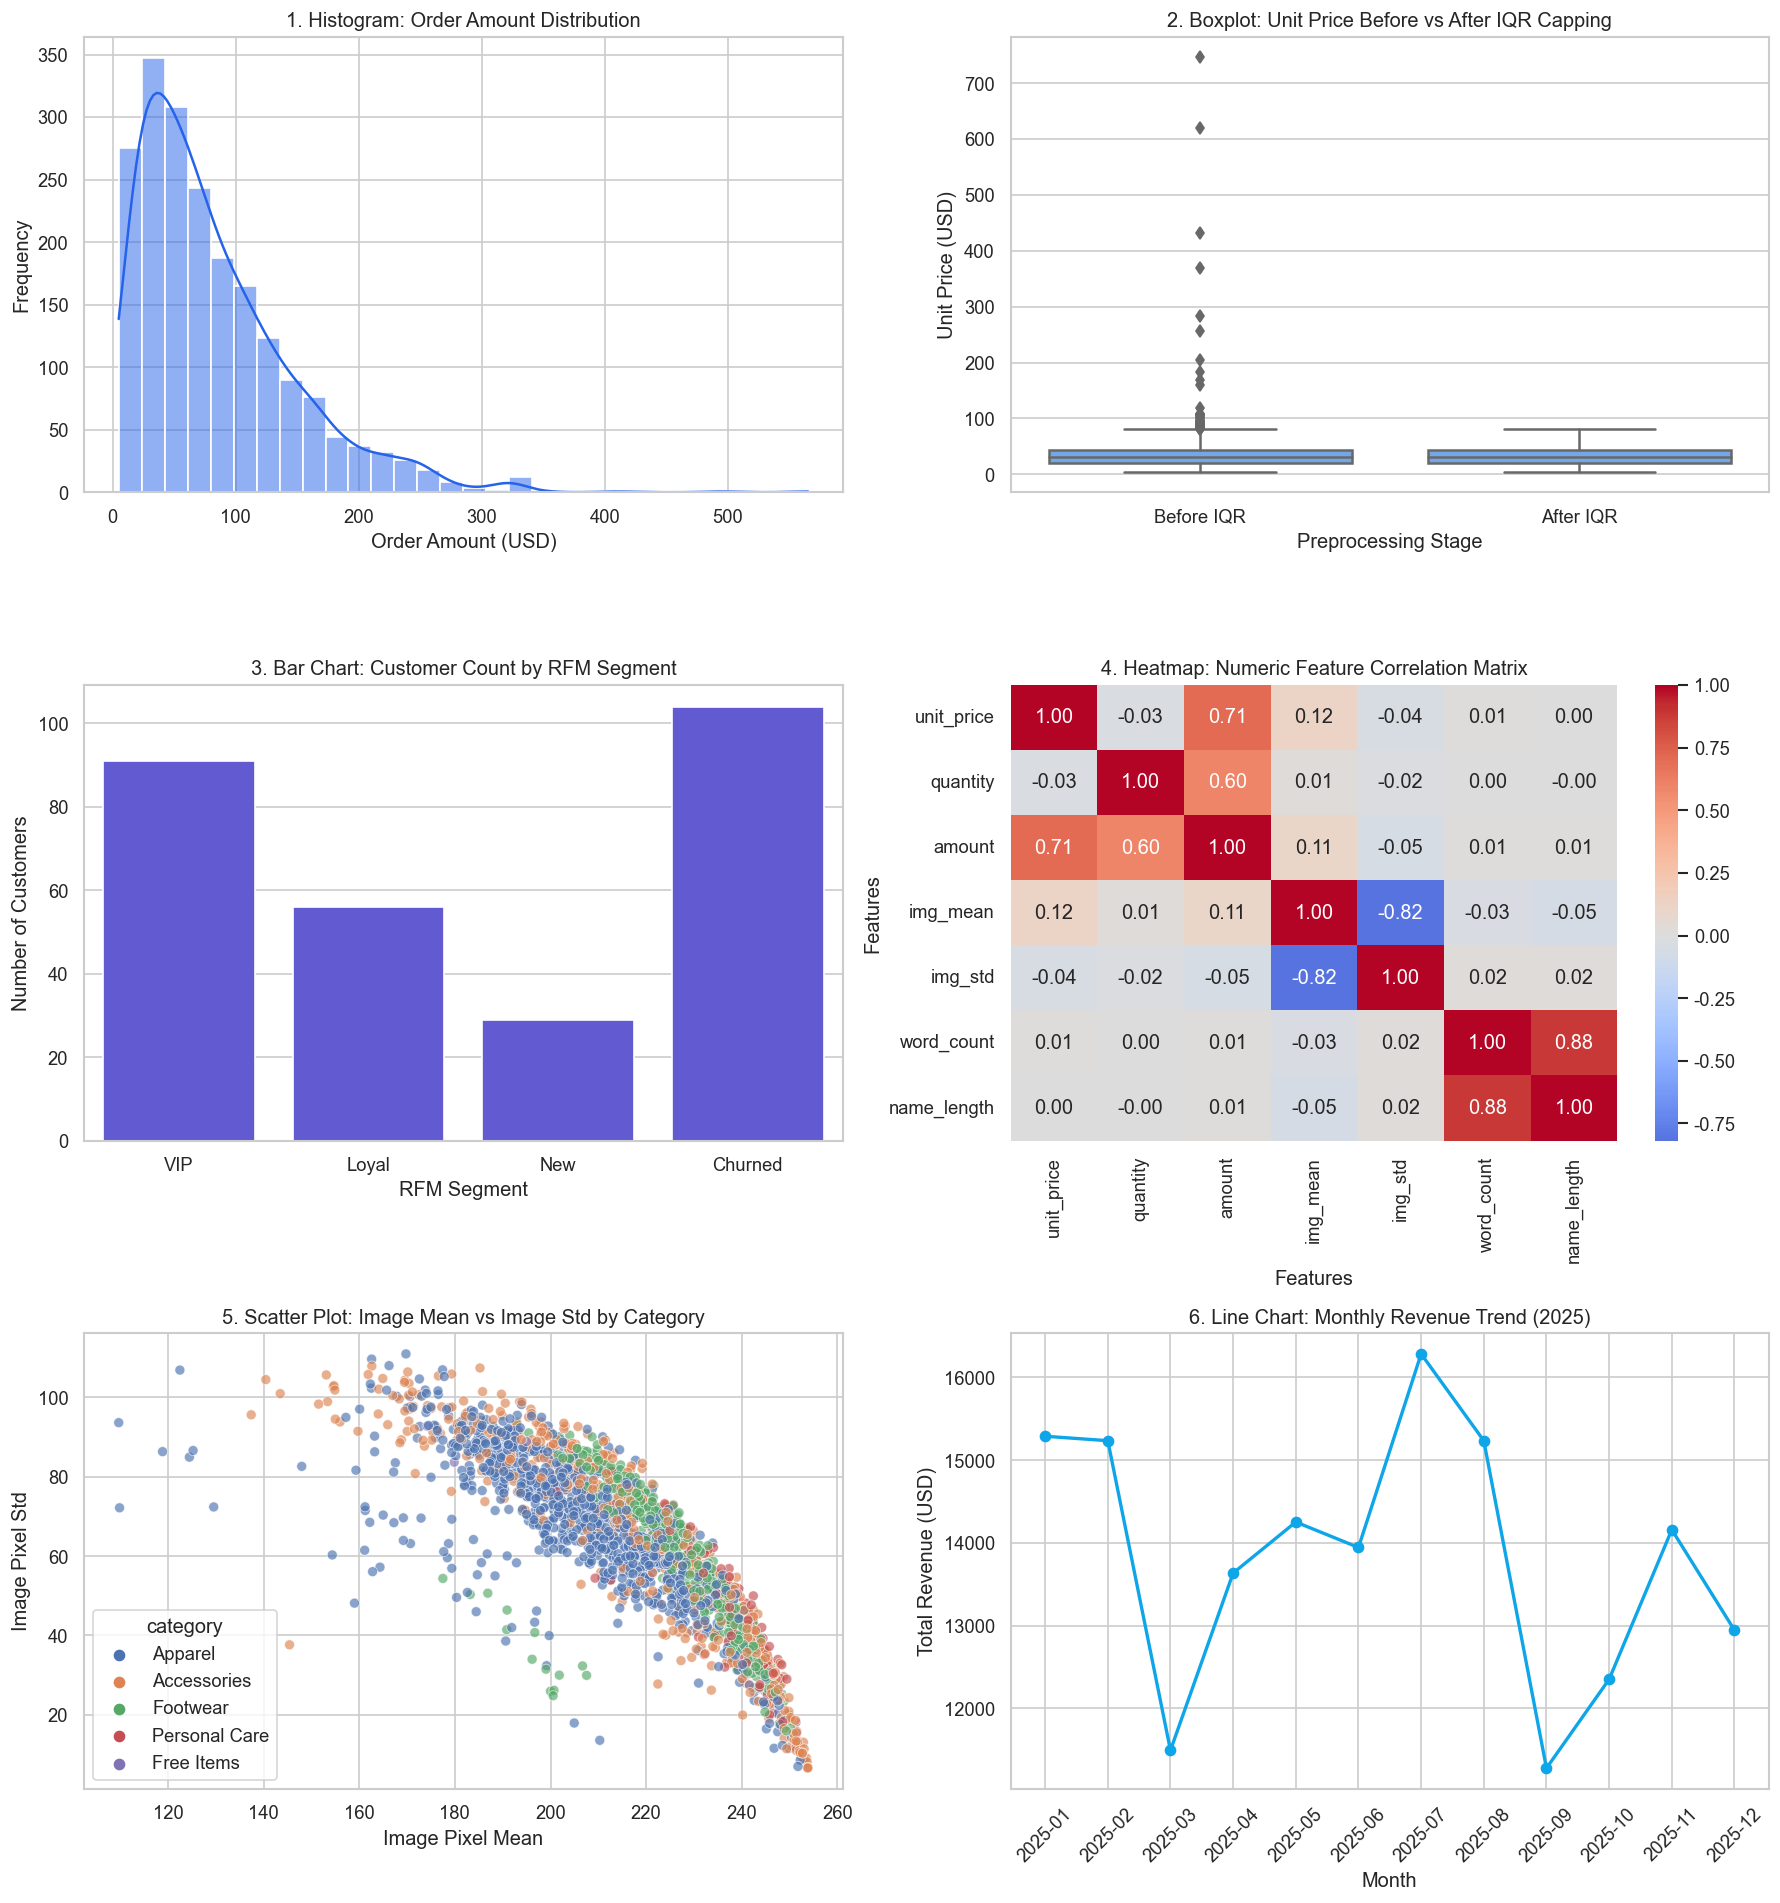

In [6]:
df_clean = analyzer.df.copy()
rfm = analyzer.calculate_rfm()

fig, axes = plt.subplots(3, 2, figsize=(15, 16))

# 1. Histogram: amount distribution
sns.histplot(df_clean['amount'], bins=30, kde=True, ax=axes[0, 0], color='#2563EB')
axes[0, 0].set_title('1. Histogram: Order Amount Distribution')
axes[0, 0].set_xlabel('Order Amount (USD)')
axes[0, 0].set_ylabel('Frequency')

# 2. Boxplot: unit_price before vs after IQR capping
bp_df = pd.DataFrame({'Before IQR': price_before, 'After IQR': price_after}).melt(var_name='Stage', value_name='Unit Price')
sns.boxplot(data=bp_df, x='Stage', y='Unit Price', ax=axes[0, 1], color='#60A5FA')
axes[0, 1].set_title('2. Boxplot: Unit Price Before vs After IQR Capping')
axes[0, 1].set_xlabel('Preprocessing Stage')
axes[0, 1].set_ylabel('Unit Price (USD)')

# 3. Bar chart: RFM segment customer counts
seg_counts = rfm['Segment'].value_counts().reindex(['VIP', 'Loyal', 'New', 'Churned'])
sns.barplot(x=seg_counts.index, y=seg_counts.values, ax=axes[1, 0], color='#4F46E5')
axes[1, 0].set_title('3. Bar Chart: Customer Count by RFM Segment')
axes[1, 0].set_xlabel('RFM Segment')
axes[1, 0].set_ylabel('Number of Customers')

# 4. Heatmap: correlation matrix
sns.heatmap(stats['corr_matrix'], annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('4. Heatmap: Numeric Feature Correlation Matrix')
axes[1, 1].set_xlabel('Features')
axes[1, 1].set_ylabel('Features')

# 5. Scatter plot: img_mean vs img_std
sns.scatterplot(data=df_clean, x='img_mean', y='img_std', hue='category', alpha=0.65, ax=axes[2, 0])
axes[2, 0].set_title('5. Scatter Plot: Image Mean vs Image Std by Category')
axes[2, 0].set_xlabel('Image Pixel Mean')
axes[2, 0].set_ylabel('Image Pixel Std')

# 6. Line chart: monthly revenue trend
monthly_sales = df_clean.assign(month=df_clean['order_date'].dt.to_period('M').astype(str)).groupby('month')['amount'].sum()
axes[2, 1].plot(monthly_sales.index, monthly_sales.values, marker='o', linewidth=2, color='#0EA5E9')
axes[2, 1].set_title('6. Line Chart: Monthly Revenue Trend (2025)')
axes[2, 1].set_xlabel('Month')
axes[2, 1].set_ylabel('Total Revenue (USD)')
axes[2, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 6. RFM 기반 고객 세분화 결과
고객별 Recency(최근 구매 경과일), Frequency(구매 빈도), Monetary(총 구매금액)를 산출하고 4개 세그먼트 특징을 요약합니다.

In [7]:
rfm_summary = rfm.groupby('Segment').agg(
    customers=('customer_id', 'count'),
    avg_recency=('Recency', 'mean'),
    avg_frequency=('Frequency', 'mean'),
    avg_monetary=('Monetary', 'mean'),
    total_revenue=('Monetary', 'sum'),
).round(2)
rfm_summary['revenue_share_pct'] = (rfm_summary['total_revenue'] / rfm_summary['total_revenue'].sum() * 100).round(2)
display(rfm_summary)

,customers,avg_recency,avg_frequency,avg_monetary,total_revenue,revenue_share_pct
Segment,,,,,,
Churned,104,181.38,2.04,186.75,19421.55,11.69
Loyal,56,69.91,7.14,561.10,31421.46,18.92
New,29,20.48,2.41,169.06,4902.81,2.95
VIP,91,19.14,14.48,1212.75,110360.67,66.44


### RFM 세분화 요약
- **VIP** 그룹은 전체 고객의 약 `32.5%`(91명)이면서 평균 구매 빈도 `14.48회`, 평균 구매 금액 `$1,212.75`로 전체 매출의 핵심 비중을 차지합니다.
- **Churned** 그룹은 `104명`(37.1%)으로 가장 많은 인원을 차지하며 평균 미구매 기간이 `181.38일`에 달해 재활성화 캠페인이 시급합니다.